## Лабораторная работа №3. Кластеризация

Цель работы: изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

Постановка задачи:
1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.



## Импорт библиотек

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import shapiro, skew
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    jaccard_score
)

from sklearn.feature_selection import mutual_info_classif, f_classif

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

## Загрузка датасета

In [35]:
df = pd.read_csv('iris.csv')

print("Первые пять строк датасета:")
display(df.head())

print("Размерность датасета:", df.shape)

print("\nИнформация о датасете:")
df.info()

print("\nКоличество пропусков:")
print(df.isnull().sum())

print("\nСтатистическое описание:")
display(df.describe())

Первые пять строк датасета:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Размерность датасета: (150, 5)

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Количество пропусков:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Статистическое описание:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## Первичный анализ данных

Числовые признаки:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

Количество объектов каждого вида:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Типы данных:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object


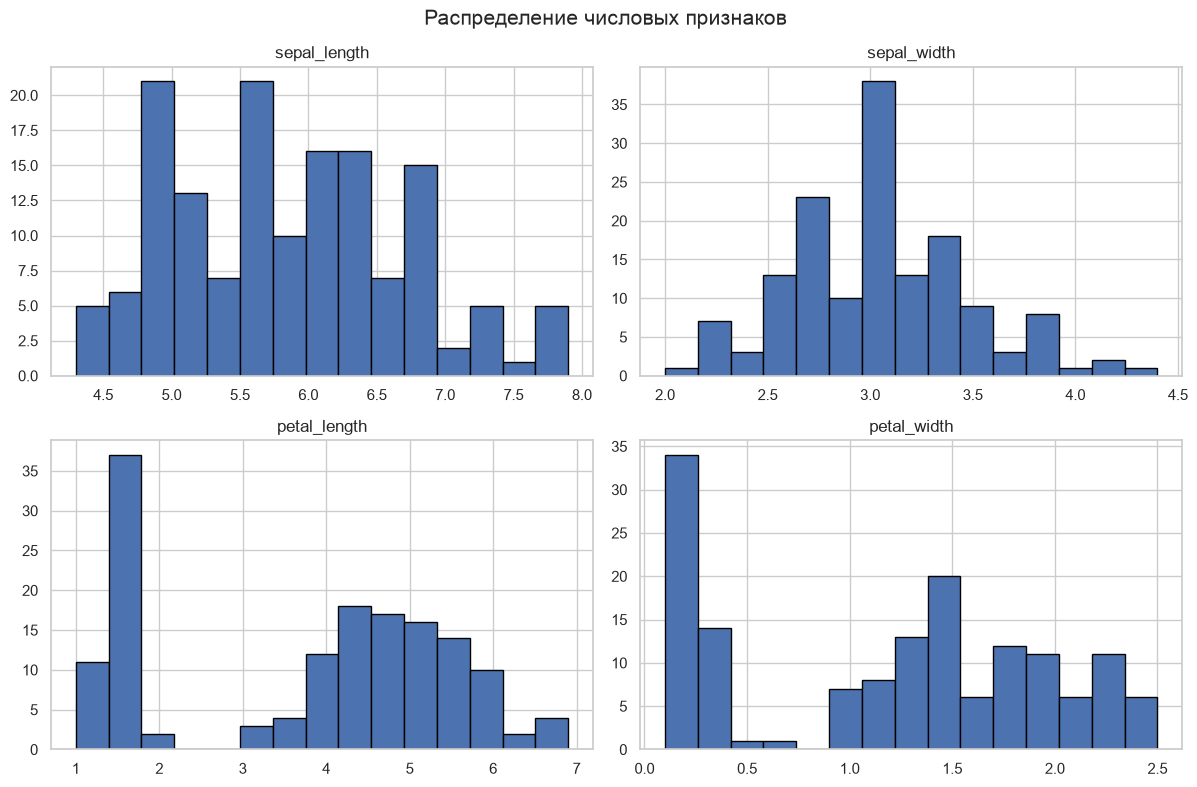


Признак: sepal_length
Статистика Шапиро: 0.9761
p-value: 0.010181
Распределение статистически отличается от нормального

Признак: sepal_width
Статистика Шапиро: 0.9838
p-value: 0.075179
Распределение статистически не отличается от нормального

Признак: petal_length
Статистика Шапиро: 0.8764
p-value: 0.000000
Распределение статистически отличается от нормального

Признак: petal_width
Статистика Шапиро: 0.9026
p-value: 0.000000
Распределение статистически отличается от нормального


In [36]:
X = df.drop('species', axis=1)
y = df['species']

print("Числовые признаки:")
print(X.columns.tolist())

print("\nКоличество объектов каждого вида:")
print(y.value_counts())

print("\nТипы данных:")
print(df.dtypes)

X.hist(
    bins=15,
    figsize=(12, 8),
    edgecolor='black'
)

plt.suptitle('Распределение числовых признаков', fontsize=15)
plt.tight_layout()
plt.show()

for column in X.columns:
    statistic, p_value = shapiro(X[column])

    print(f"\nПризнак: {column}")
    print(f"Статистика Шапиро: {statistic:.4f}")
    print(f"p-value: {p_value:.6f}")

    if p_value > 0.05:
        print("Распределение статистически не отличается от нормального")
    else:
        print("Распределение статистически отличается от нормального")

## Проверка выбросов

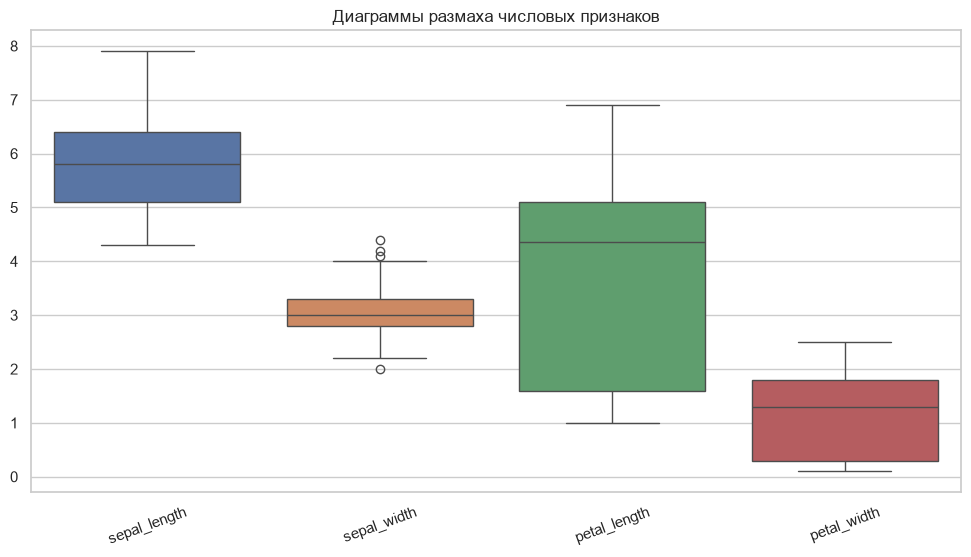

Количество выбросов по методу IQR:

sepal_length: 0
sepal_width: 4
petal_length: 0
petal_width: 0


In [37]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=X)
plt.title('Диаграммы размаха числовых признаков')
plt.xticks(rotation=20)
plt.show()

print("Количество выбросов по методу IQR:\n")

for column in X.columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X[
        (X[column] < lower) |
        (X[column] > upper)
    ]

    print(f"{column}: {len(outliers)}")

## Оценка информационной значимости признаков

,Признак,Взаимная информация
2,petal_length,0.992573
3,petal_width,0.985643
0,sepal_length,0.511365
1,sepal_width,0.289759


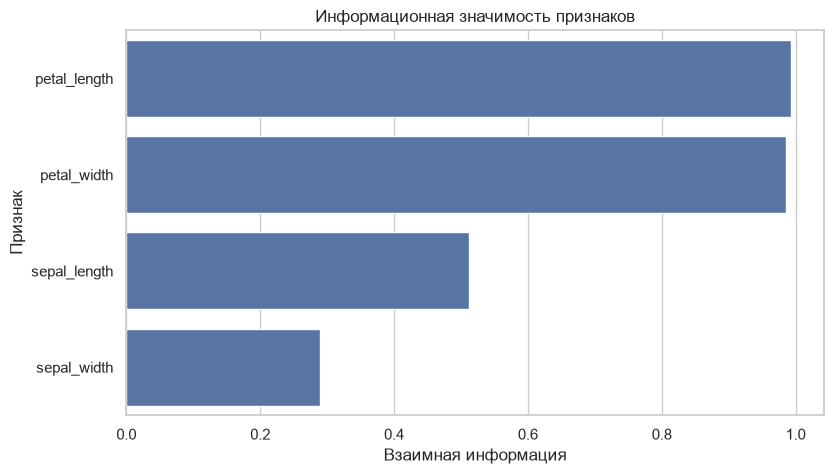

,Признак,F-статистика,p-value
2,petal_length,1179.034328,3.051976e-91
3,petal_width,959.324406,4.376957e-85
0,sepal_length,119.264502,1.669669e-31
1,sepal_width,47.364461,1.327917e-16


In [38]:
mi = mutual_info_classif(
    X,
    y,
    random_state=42
)

importance = pd.DataFrame({
    'Признак': X.columns,
    'Взаимная информация': mi
})

importance = importance.sort_values(
    by='Взаимная информация',
    ascending=False
)

display(importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x='Взаимная информация',
    y='Признак'
)

plt.title('Информационная значимость признаков')
plt.show()


f_values, p_values = f_classif(X, y)

anova = pd.DataFrame({
    'Признак': X.columns,
    'F-статистика': f_values,
    'p-value': p_values
})

display(anova.sort_values(
    by='F-статистика',
    ascending=False
))

## Стандартизация признаков

In [39]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Стандартизированные данные:")
display(X_scaled.head())

print("\nСредние значения:")
print(X_scaled.mean().round(4))

print("\nСтандартные отклонения:")
print(X_scaled.std().round(4))

Стандартизированные данные:


,sepal_length,sepal_width,petal_length,petal_width
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977



Средние значения:
sepal_length   -0.0
sepal_width    -0.0
petal_length    0.0
petal_width    -0.0
dtype: float64

Стандартные отклонения:
sepal_length    1.0034
sepal_width     1.0034
petal_length    1.0034
petal_width     1.0034
dtype: float64


## Матрица диаграмм рассеивания

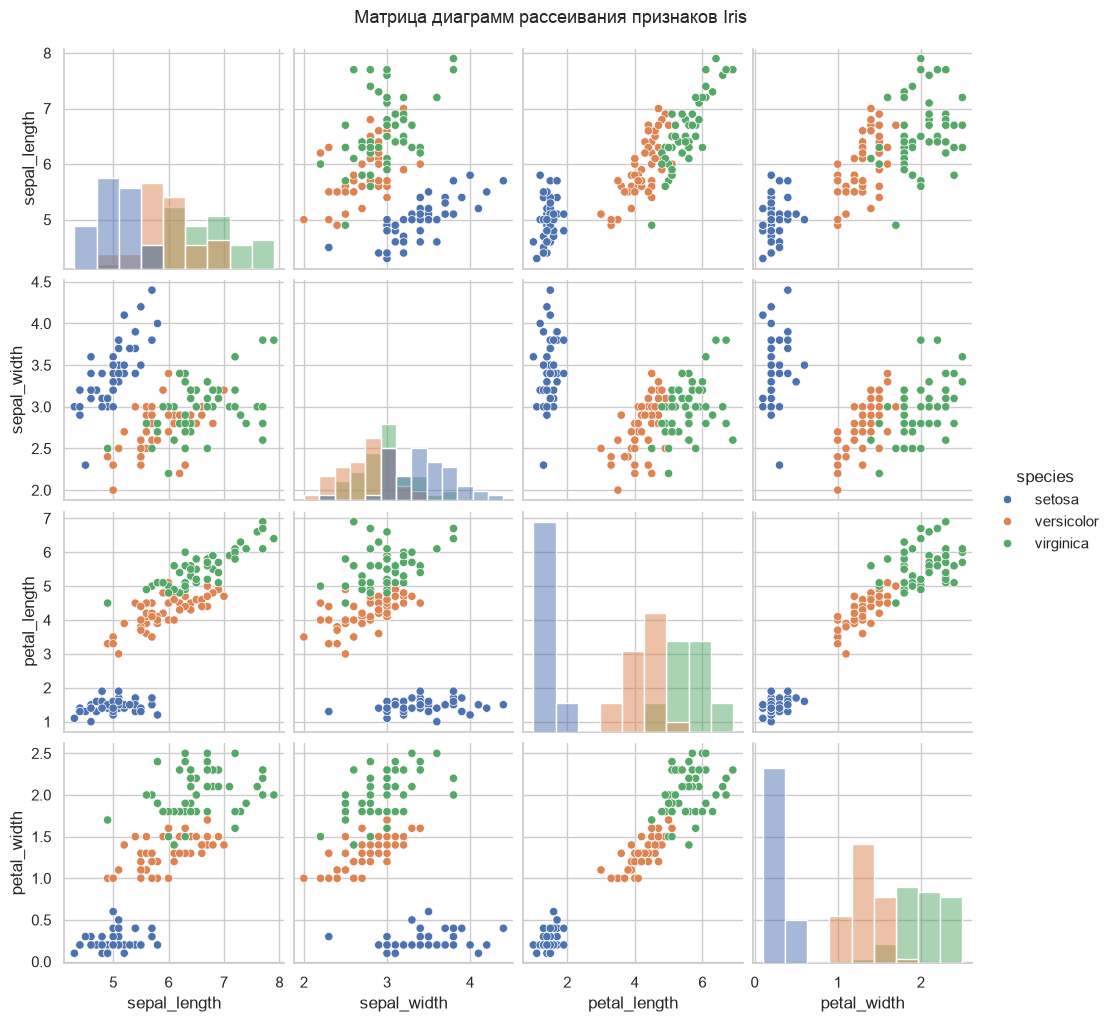

In [40]:
sns.pairplot(
    df,
    vars=X.columns,
    hue='species',
    diag_kind='hist'
)

plt.suptitle(
    'Матрица диаграмм рассеивания признаков Iris',
    y=1.02
)

plt.show()

## Определение оптимального количества кластеров

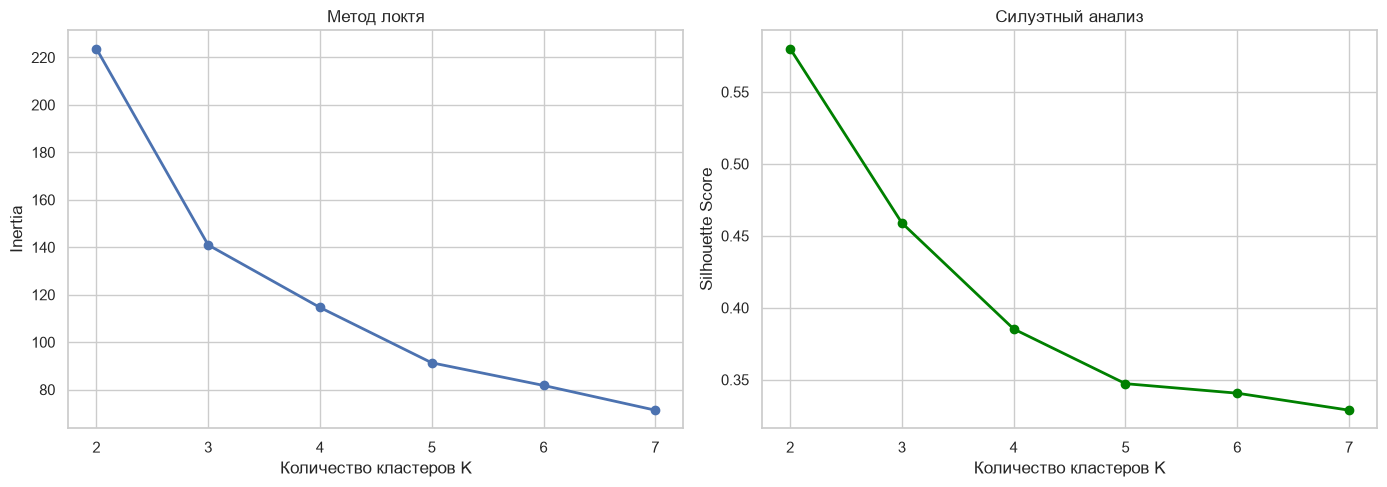

K=2: Inertia=223.73, Silhouette=0.5802
K=3: Inertia=140.97, Silhouette=0.4590
K=4: Inertia=114.62, Silhouette=0.3853
K=5: Inertia=91.30, Silhouette=0.3473
K=6: Inertia=81.76, Silhouette=0.3407
K=7: Inertia=71.32, Silhouette=0.3288


In [41]:
inertia = []
silhouette_scores = []

K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    list(K_range),
    inertia,
    marker='o',
    linewidth=2
)

axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Количество кластеров K')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(list(K_range))
axes[0].grid(True)

axes[1].plot(
    list(K_range),
    silhouette_scores,
    marker='o',
    linewidth=2,
    color='green'
)

axes[1].set_title('Силуэтный анализ')
axes[1].set_xlabel('Количество кластеров K')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(K_range))
axes[1].grid(True)

plt.tight_layout()
plt.show()

for k, inertia_value, silhouette_value in zip(
    K_range,
    inertia,
    silhouette_scores
):
    print(
        f"K={k}: "
        f"Inertia={inertia_value:.2f}, "
        f"Silhouette={silhouette_value:.4f}"
    )

## Кластеризация методом K-means

Количество объектов в каждом кластере:
KMeans_cluster
0    53
1    50
2    47
Name: count, dtype: int64


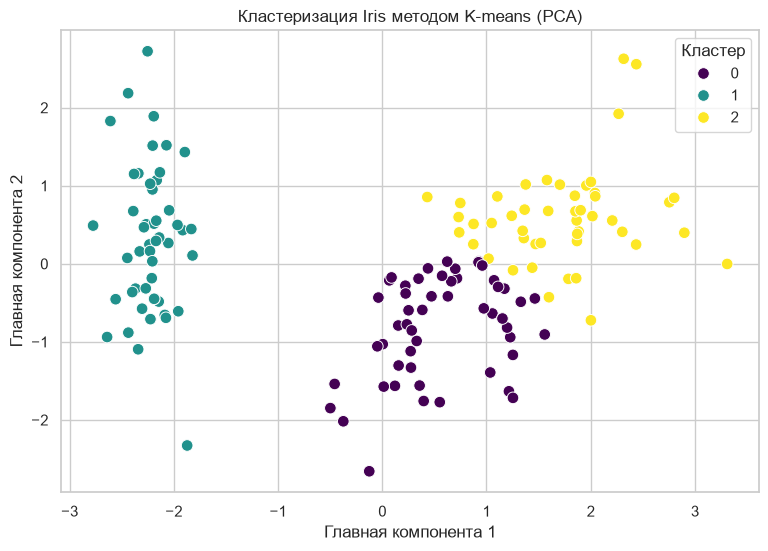

Объяснённая дисперсия PCA: 0.958


In [42]:
kmeans = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(X_scaled)

df['KMeans_cluster'] = kmeans_labels

print("Количество объектов в каждом кластере:")
print(df['KMeans_cluster'].value_counts().sort_index())

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels,
    palette='viridis',
    s=70
)

plt.title('Кластеризация Iris методом K-means (PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend(title='Кластер')
plt.show()

print(
    "Объяснённая дисперсия PCA:",
    pca.explained_variance_ratio_.sum().round(4)
)

## Иерархическая кластеризация

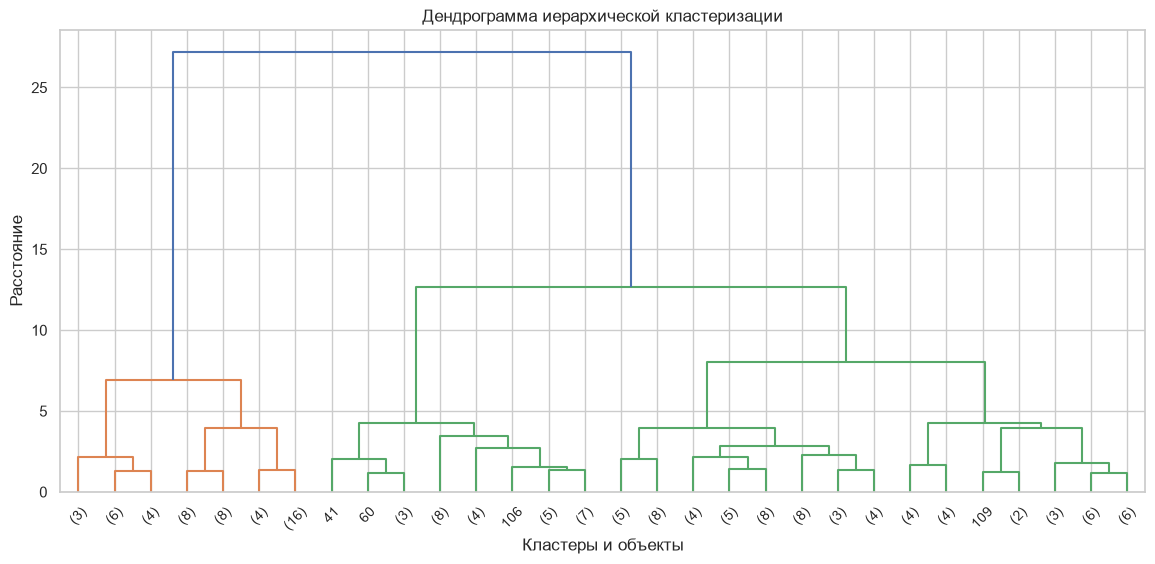

Количество объектов в каждом кластере:
Hierarchical_cluster
0    71
1    49
2    30
Name: count, dtype: int64


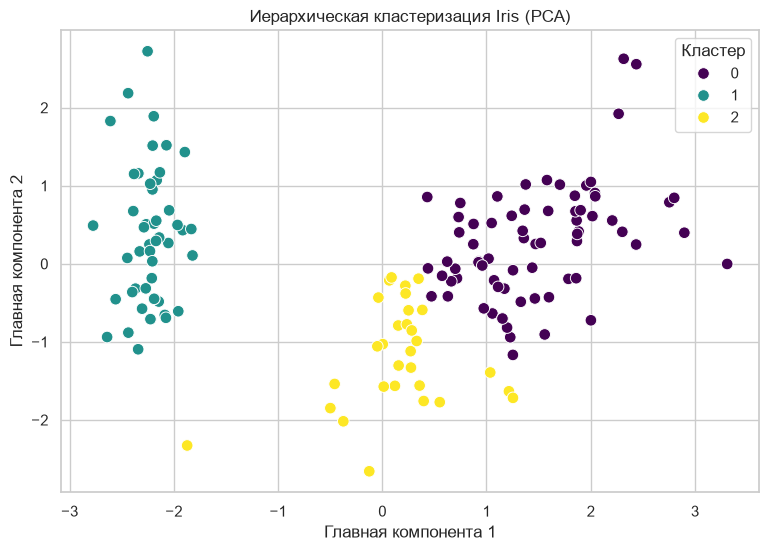

In [43]:
Z = linkage(
    X_scaled,
    method='ward'
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30
)

plt.title('Дендрограмма иерархической кластеризации')
plt.xlabel('Кластеры и объекты')
plt.ylabel('Расстояние')
plt.show()

hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

df['Hierarchical_cluster'] = hierarchical_labels

print("Количество объектов в каждом кластере:")
print(
    df['Hierarchical_cluster']
    .value_counts()
    .sort_index()
)


plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=hierarchical_labels,
    palette='viridis',
    s=70
)

plt.title('Иерархическая кластеризация Iris (PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend(title='Кластер')
plt.show()

## Оценка качества кластеризации

In [44]:
def evaluate_clustering(X_data, labels, method_name):

    silhouette = silhouette_score(X_data, labels)

    calinski = calinski_harabasz_score(
        X_data,
        labels
    )

    davies = davies_bouldin_score(
        X_data,
        labels
    )

    return {
        'Метод': method_name,
        'Silhouette Score': silhouette,
        'Calinski-Harabasz': calinski,
        'Davies-Bouldin': davies
    }


results = []

results.append(
    evaluate_clustering(
        X_scaled,
        kmeans_labels,
        'K-means'
    )
)

results.append(
    evaluate_clustering(
        X_scaled,
        hierarchical_labels,
        'Hierarchical'
    )
)

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Метод,Silhouette Score,Calinski-Harabasz,Davies-Bouldin
0,K-means,0.4590,239.3418,0.8354
1,Hierarchical,0.4455,220.2604,0.8059


## Внешние метрики качества

In [45]:
def external_metrics(y_true, labels, method_name):

    return {
        'Метод': method_name,
        'Rand Index': rand_score(y_true, labels),
        'Adjusted Rand Index': adjusted_rand_score(
            y_true, labels
        ),
        'NMI': normalized_mutual_info_score(
            y_true, labels
        ),
        'Homogeneity': homogeneity_score(
            y_true, labels
        ),
        'Completeness': completeness_score(
            y_true, labels
        ),
        'V-measure': v_measure_score(
            y_true, labels
        )
    }


external_results = pd.DataFrame([
    external_metrics(y, kmeans_labels, 'K-means'),
    external_metrics(y, hierarchical_labels, 'Hierarchical')
])

display(external_results.round(4))

,Метод,Rand Index,Adjusted Rand Index,NMI,Homogeneity,Completeness,V-measure
0,K-means,0.8322,0.6201,0.6595,0.6591,0.6598,0.6595
1,Hierarchical,0.8252,0.6153,0.6755,0.6579,0.6940,0.6755


## Центры кластеров и их интерпретация

In [46]:
centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers_df = pd.DataFrame(
    centers,
    columns=X.columns
)

centers_df.index.name = 'Номер кластера'

print("Центры кластеров K-means:")
display(centers_df.round(2))

print("Профили кластеров K-means:")

display(
    df.groupby('KMeans_cluster')[list(X.columns)]
    .mean()
    .round(2)
)

print("Профили иерархической кластеризации:")

display(
    df.groupby('Hierarchical_cluster')[list(X.columns)]
    .mean()
    .round(2)
)


print("K-means:")
display(pd.crosstab(
    df['KMeans_cluster'],
    df['species']
))

print("Hierarchical:")
display(pd.crosstab(
    df['Hierarchical_cluster'],
    df['species']
))

Центры кластеров K-means:


,sepal_length,sepal_width,petal_length,petal_width
Номер кластера,,,,
0,5.80,2.67,4.37,1.41
1,5.01,3.42,1.46,0.24
2,6.78,3.10,5.51,1.97


Профили кластеров K-means:


,sepal_length,sepal_width,petal_length,petal_width
KMeans_cluster,,,,
0,5.80,2.67,4.37,1.41
1,5.01,3.42,1.46,0.24
2,6.78,3.10,5.51,1.97


Профили иерархической кластеризации:


,sepal_length,sepal_width,petal_length,petal_width
Hierarchical_cluster,,,,
0,6.55,2.99,5.27,1.85
1,5.02,3.44,1.47,0.24
2,5.53,2.57,3.93,1.21


K-means:


species,setosa,versicolor,virginica
KMeans_cluster,,,
0,0,39,14
1,50,0,0
2,0,11,36


Hierarchical:


species,setosa,versicolor,virginica
Hierarchical_cluster,,,
0,0,23,48
1,49,0,0
2,1,27,2


## Внутрикластерные и межкластерные расстояния

In [47]:
from scipy.spatial.distance import cdist

def cluster_distances(X_data, labels):

    unique_labels = np.unique(labels)

    centers = []
    intra_distances = []

    for cluster in unique_labels:

        cluster_data = X_data[labels == cluster]

        center = cluster_data.mean(axis=0)

        centers.append(center)

        distances = np.linalg.norm(
            cluster_data - center,
            axis=1
        )

        intra_distances.append(distances.mean())

    centers = np.array(centers)

    inter_distances = cdist(
        centers,
        centers
    )

    print("Средние внутрикластерные расстояния:")

    for cluster, distance in zip(
        unique_labels,
        intra_distances
    ):
        print(f"Кластер {cluster}: {distance:.4f}")

    print("\nМатрица расстояний между центрами:")

    display(pd.DataFrame(
        inter_distances,
        index=unique_labels,
        columns=unique_labels
    ).round(3))


print("K-means:")
cluster_distances(X_scaled, kmeans_labels)

print("\nИерархическая кластеризация:")
cluster_distances(X_scaled, hierarchical_labels)

K-means:
Средние внутрикластерные расстояния:
Кластер 0: 0.8589
Кластер 1: 0.8225
Кластер 2: 0.9142

Матрица расстояний между центрами:


,0,1,2
0,0.000,2.998,1.823
1,2.998,0.000,3.955
2,1.823,3.955,0.000



Иерархическая кластеризация:
Средние внутрикластерные расстояния:
Кластер 0: 0.9845
Кластер 1: 0.7872
Кластер 2: 0.8190

Матрица расстояний между центрами:


,0,1,2
0,0.000,3.698,1.948
1,3.698,0.000,2.837
2,1.948,2.837,0.000


## Исследование влияния количества кластеров

,Количество кластеров,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,223.7320,0.5802,248.9034,0.5976
1,3,140.9658,0.4590,239.3418,0.8354
2,4,114.6179,0.3853,206.0929,0.8727
3,5,91.2954,0.3473,201.9875,0.9406
4,6,81.7566,0.3407,182.5591,1.0077
5,7,71.3198,0.3288,176.6719,0.9939
6,8,62.6518,0.3404,173.9854,0.9124


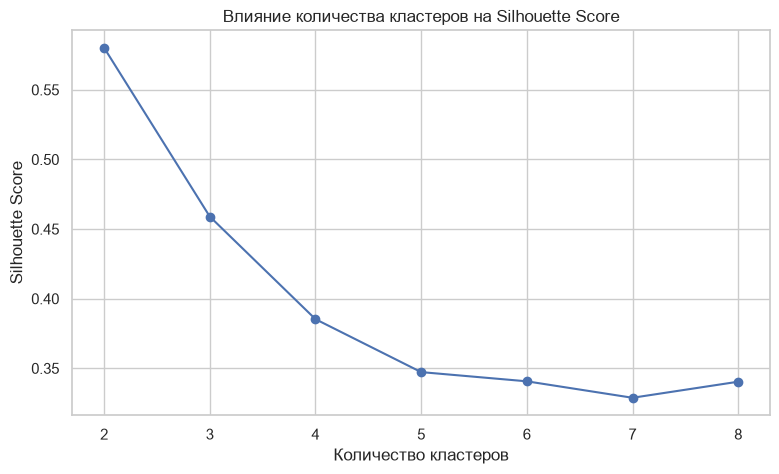

In [48]:
sensitivity = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    sensitivity.append({
        'Количество кластеров': k,
        'Inertia': model.inertia_,
        'Silhouette': silhouette_score(
            X_scaled,
            labels
        ),
        'Calinski-Harabasz': calinski_harabasz_score(
            X_scaled,
            labels
        ),
        'Davies-Bouldin': davies_bouldin_score(
            X_scaled,
            labels
        )
    })

sensitivity_df = pd.DataFrame(sensitivity)

display(sensitivity_df.round(4))

plt.figure(figsize=(9, 5))

plt.plot(
    sensitivity_df['Количество кластеров'],
    sensitivity_df['Silhouette'],
    marker='o'
)

plt.title('Влияние количества кластеров на Silhouette Score')
plt.xlabel('Количество кластеров')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.show()

## Устойчивость кластеризации

,Метод,Средняя устойчивость ARI,Стандартное отклонение,Минимальная устойчивость,Максимальная устойчивость
0,K-means,0.9418,0.0609,0.7824,1.0
1,Hierarchical,0.6158,0.1363,0.4638,1.0


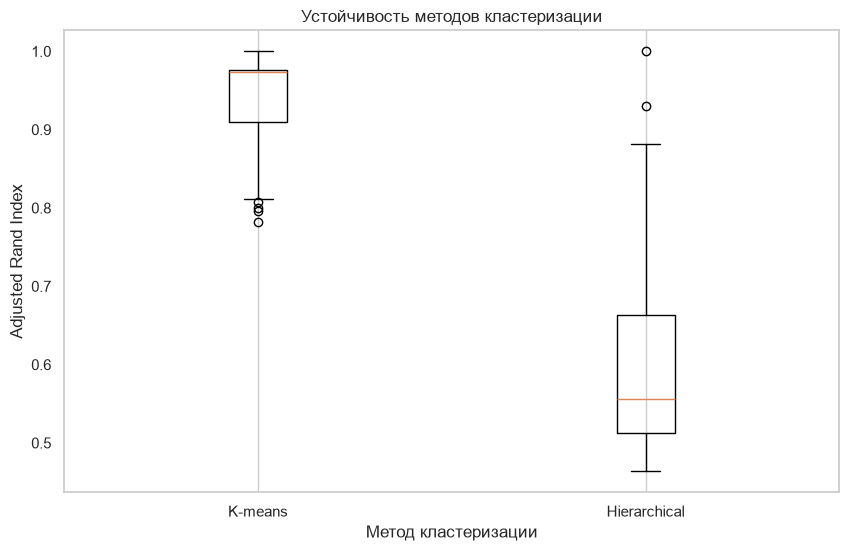

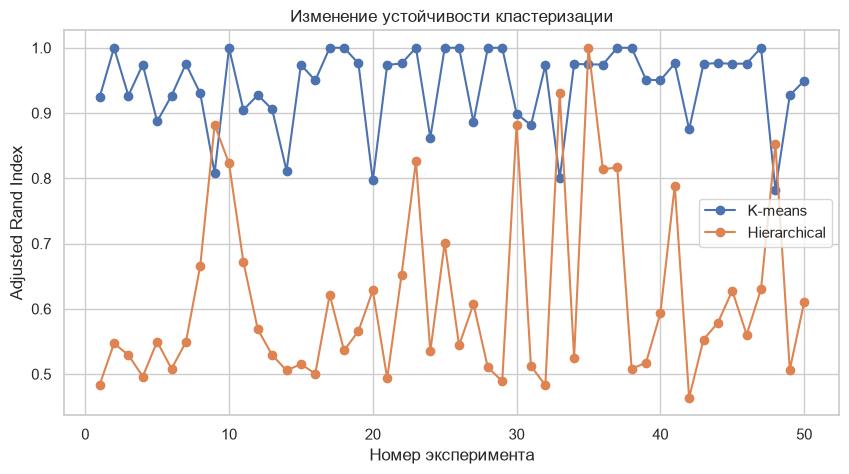

In [49]:
from sklearn.metrics import adjusted_rand_score

n_iterations = 50
sample_size = 0.8

rng = np.random.default_rng(42)

stability_results = {
    'K-means': [],
    'Hierarchical': []
}

for i in range(n_iterations):

    indices = rng.choice(
        len(X_scaled),
        size=int(len(X_scaled) * sample_size),
        replace=False
    )

    X_sample = X_scaled.iloc[indices]

    reference_kmeans = kmeans_labels[indices]
    reference_hierarchical = hierarchical_labels[indices]

    kmeans_model = KMeans(
        n_clusters=3,
        n_init=10,
        random_state=42 + i
    )

    kmeans_sample_labels = kmeans_model.fit_predict(
        X_sample
    )

    hierarchical_model = AgglomerativeClustering(
        n_clusters=3,
        linkage='ward'
    )

    hierarchical_sample_labels = hierarchical_model.fit_predict(
        X_sample
    )

    ari_kmeans = adjusted_rand_score(
        reference_kmeans,
        kmeans_sample_labels
    )

    ari_hierarchical = adjusted_rand_score(
        reference_hierarchical,
        hierarchical_sample_labels
    )

    stability_results['K-means'].append(ari_kmeans)
    stability_results['Hierarchical'].append(ari_hierarchical)

stability_df = pd.DataFrame({
    'Метод': ['K-means', 'Hierarchical'],
    'Средняя устойчивость ARI': [
        np.mean(stability_results['K-means']),
        np.mean(stability_results['Hierarchical'])
    ],
    'Стандартное отклонение': [
        np.std(stability_results['K-means']),
        np.std(stability_results['Hierarchical'])
    ],
    'Минимальная устойчивость': [
        np.min(stability_results['K-means']),
        np.min(stability_results['Hierarchical'])
    ],
    'Максимальная устойчивость': [
        np.max(stability_results['K-means']),
        np.max(stability_results['Hierarchical'])
    ]
})

display(stability_df.round(4))


plt.figure(figsize=(10, 6))

plt.boxplot(
    [
        stability_results['K-means'],
        stability_results['Hierarchical']
    ],
    tick_labels=['K-means', 'Hierarchical']
)

plt.title('Устойчивость методов кластеризации')
plt.ylabel('Adjusted Rand Index')
plt.xlabel('Метод кластеризации')
plt.grid(axis='y')

plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    range(1, n_iterations + 1),
    stability_results['K-means'],
    marker='o',
    label='K-means'
)

plt.plot(
    range(1, n_iterations + 1),
    stability_results['Hierarchical'],
    marker='o',
    label='Hierarchical'
)

plt.title('Изменение устойчивости кластеризации')
plt.xlabel('Номер эксперимента')
plt.ylabel('Adjusted Rand Index')
plt.legend()
plt.grid(True)

plt.show()